# Configure and diagnose a GP fit

In [1]:
%matplotlib inline

# Import the analysis and plotting tools and record the package version.
import numpy as np
import matplotlib.pyplot as plt
import nahiku
from nahiku import Nahiku
print(f"Nāhiku {nahiku.__version__}")

# Set the display resolution and simplify plot borders.
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

/tmp/nahiku-02/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Nāhiku 0.2.0


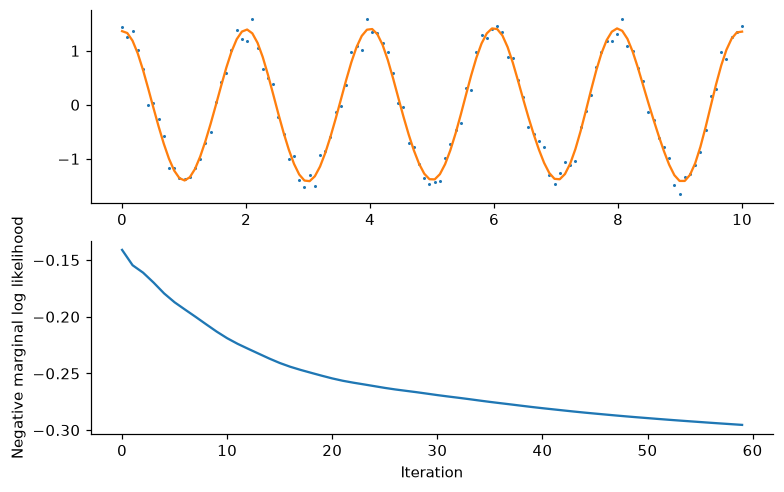

In [2]:
# Generate a 2-day signal with known white measurement noise and no red noise.
lc = Nahiku.from_synthetic_noise(n_points=120, period=2, red_noise=0, white_noise=.03)

# Standardize flux and errors, then initialize and fit a quasi-periodic GP.
# Noise is additional to measurement errors and is specified in standardized flux units.
# Use explicit training settings for this short example rather than the package defaults.
lc.standardize().fit_gp(period=2, length_scale=4, noise=.1, iterations=60,
                       learning_rate=.05, optimizer="adam", patience=15)

# Predict the latent signal and its uncertainty at the observed timestamps.
mean, latent_std = lc.predict()

# Include learned noise and stored measurement errors for observation uncertainty.
_, observation_std = lc.predict(include_noise=True)
assert np.all(observation_std >= latent_std)

# Compare the fitted mean with the standardized observations.
fig, axes = plt.subplots(2, 1, figsize=(8, 5))
axes[0].plot(lc.time, lc.flux, ".", ms=2)
axes[0].plot(lc.time, mean)

# Inspect the recorded training objective; a lower negative log likelihood is better.
axes[1].plot(lc.fit_diagnostics["losses"])
axes[1].set(xlabel="Iteration", ylabel="Negative marginal log likelihood");

## Interpret the result

The upper panel compares the standardized observations with the GP posterior mean; the lower panel shows the training loss. The two prediction calls distinguish uncertainty in the latent signal from observation uncertainty, which also includes learned additional noise and stored measurement errors. The assertion checks their ordering; the figure does not display uncertainty bands.

The recurrence period is initialized at the known synthetic value. The example specifies its own training settings. Package defaults are Adam, `learning_rate=0.01`, `iterations=1000`, and `patience=1`. Stopping checks begin after the warm-up boundary (`min_iterations`, default `iterations // 10`), and stop when consecutive non-improvements exceed patience. `early_stopping=False` disables this rule. Reaching a stopping rule or iteration limit does not establish convergence; inspect the loss and sensitivity to initialization and kernel choice.

`save_state="last"` keeps the final state; `"best"` selects the lowest evaluated training objective. The default `objective="mll"` fits the full GP; `"mse"` fits only the training-mode prior mean. CPU and float64 are defaults, with explicit float32 and CUDA options. Optional `set_noise_equal_to_var_residuals=True` resets additional noise variance from training residuals before inference caches are built; known measurement errors remain separate. Use `return_mll=True` for `(lc, final_mll)` and `lc.plot_fit()` for loss/covariance diagnostics.

For period-informed initialization and constraints, use `qp_constraints="period-informed"` without explicit `length_scale`, `noise`, or `mean` overrides. Supply a GPyTorch kernel/mean for advanced control, or use `kernel="rbf"` when no recurrence period is justified.

Consult the API reference for parameter and return-value details.